# Model 1 — Congestion Forecast (EV Charging ActionEngine)

**Goal:** predict how many cars arrive at each station per 30-minute slot, 24–72 h ahead, then convert arrivals into an expected waiting time with an M/M/c queue. The queue step is what lets Model 2 (charger health) plug in: a faulty charger means `c` drops by one and the wait is recomputed.

**Data:** ACN-Data static snapshot (Caltech / JPL), `tongxin-li/ACN-Data-Static`. Cite: Lee, Li & Low, *ACN-Data: Analysis and Applications of an Open EV Charging Dataset*, ACM e-Energy 2019. Check the ACN-Data site's terms before redistributing anything.

**How the notebook works**
1. List all 85k session files from the repo *without downloading them* (arrival time and charger id are encoded in each file name).
2. Download a random **sample** of sessions per station, only to learn charge durations and energy.
3. Build a station × 30-min arrivals table, add features, train LightGBM, and compare against **"same slot last week"**.
4. Convert arrivals → wait time (M/M/c), show the what-if "one charger down", and export files for the priority engine.

**Things to know about this dataset (say these in the pitch, don't hide them)**
- `session data/caltech_sessions.json` in the repo is empty, so sessions are rebuilt from the time-series files.
- **JPL files have no energy / power columns**, only charging current. Energy is estimated as current × 208 V.
- These are **workplace** stations: long parking, weekday-morning arrivals, almost nothing at weekends. Malaysian R&R behaviour is different. The Malaysian festive multipliers are applied later (workstream A) and are assumptions.
- Timestamps are UTC; local features use `America/Los_Angeles`. For the Malaysian corridor change `LOCAL_TZ` and `holidays.Malaysia`.
- Holidays here are US holidays. Their effect on workplace demand (a dip) is the *opposite* sign to Raya on the highway (a spike), but it exercises the same holiday-flag mechanism.

## 1. Setup and configuration

In [1]:
import importlib, subprocess, sys
for pkg, mod in [("lightgbm","lightgbm"),("holidays","holidays"),("requests","requests"),("matplotlib","matplotlib"),("scikit-learn","sklearn")]:
    try: importlib.import_module(mod)
    except ImportError: subprocess.check_call([sys.executable,"-m","pip","install","-q",pkg])

import io, json, math, urllib.parse, warnings
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
import numpy as np, pandas as pd, requests, holidays, lightgbm as lgb
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)

# ---- data ----
CACHE   = Path("acn_cache");  CACHE.mkdir(exist_ok=True)
OUT     = Path("outputs");    OUT.mkdir(exist_ok=True)
REPO_URL = "https://github.com/tongxin-li/ACN-Data-Static.git"
RAW_BASE = "https://raw.githubusercontent.com/tongxin-li/ACN-Data-Static/main/"
SITES = ["caltech/California_Garage_01", "caltech/California_Garage_02",
         "caltech/N_Wilson_Garage_01",  "caltech/S_Wilson_Garage_01",
         "jpl/Arroyo_Garage_01"]                       # each site = one "station"
MIN_SESSIONS   = 1500       # drop stations with fewer sessions inside the window
N_SAMPLE       = 400        # sessions per station downloaded to learn charge durations
ASSUMED_VOLTS  = 208.0      # only used where the file has no energy/power (JPL)
GLITCH_GAP_MIN = 10         # sessions starting sooner than this after the previous one on the same charger are dropped

# ---- time windows (UTC). Stops before COVID; test window contains Christmas / New Year / MLK ----
DATA_START = pd.Timestamp("2018-11-01", tz="UTC")
TRAIN_END  = pd.Timestamp("2019-09-30 23:30", tz="UTC")
VAL_END    = pd.Timestamp("2019-11-30 23:30", tz="UTC")
DATA_END   = pd.Timestamp("2020-02-29 23:30", tz="UTC")   # test = VAL_END .. DATA_END

# ---- forecasting ----
HORIZON_HOURS = 24          # features only use information available this long before the slot (24-72 is the brief)
LOCAL_TZ      = "America/Los_Angeles"      # Malaysia: "Asia/Kuala_Lumpur"
HOLIDAYS      = holidays.US(subdiv="CA", years=range(2018, 2022))   # Malaysia: holidays.Malaysia(...)
USE_WEATHER   = True        # Open-Meteo archive (free, no key); falls back to no-rain features if unreachable
LAT, LON      = 34.1377, -118.1253         # Pasadena (Caltech and JPL)
SEED = 42

# ---- queueing demo (R&R-scale station) ----
C_DEMO     = 4              # chargers at the demo station, as in the Seremban example
FESTIVE_MULT = 2.0          # ASSUMPTION: festive demand multiplier. Replace with the team's value.
SERVICE_MIN_OVERRIDE = 35   # ASSUMPTION: ~35-min fast-charge session at an R&R. ACN workplace sessions average ~2-4 h, so the learned
                            # value would make a 4-charger station unstable even at normal load. Set None to use the learned value.

## 2. Index the dataset (no bulk download)
A partial git clone fetches only the file *list*. Each file name looks like `1-1-178-817-2019-01-17T14-56-03-016628.csv.gz` = charger id (`1-1-178-817`) + session start time (UTC). That is enough for the arrivals target.

In [2]:
def build_index():
    idx_path = CACHE / "file_index.csv"
    if idx_path.exists():
        idx = pd.read_csv(idx_path)
    else:
        repo = CACHE / "ACN-Data-Static"
        if not repo.exists():
            subprocess.run(["git","clone","--depth","1","--filter=blob:none","--no-checkout",REPO_URL,str(repo)], check=True)
        out = subprocess.run(["git","-C",str(repo),"ls-tree","-r","--name-only","HEAD"],
                             check=True, capture_output=True, text=True).stdout.splitlines()
        idx = pd.DataFrame({"path": [p for p in out if p.endswith(".csv.gz")]})
        parts = idx["path"].str.split("/")
        idx["station"] = parts.str[1] + "/" + parts.str[2]
        m = parts.str[-1].str.extract(r"^(\d+-\d+-\d+-\d+)-(\d{4}-\d\d-\d\dT\d\d-\d\d-\d\d)")
        idx["charger_id"] = m[0]
        idx["arrival_time"] = pd.to_datetime(m[1], format="%Y-%m-%dT%H-%M-%S", utc=True)
        idx.to_csv(idx_path, index=False)
    idx["arrival_time"] = pd.to_datetime(idx["arrival_time"], utc=True)
    return idx

index = build_index()
print(f"{len(index):,} session files in the snapshot")

# generic session schema used by everything below: station, charger_id, arrival_time
# (swap datasets by producing this same table from another source)
arr = index[index["station"].isin(SITES) & index["arrival_time"].between(DATA_START, DATA_END)].copy()

# Cleaning: a charger cannot start a genuine new session seconds after the last one. Bursts like that are
# logging glitches / reconnect flicker (e.g. 192 "sessions" from 7 chargers in 4 minutes on 2018-12-06).
arr = arr.sort_values(["station","charger_id","arrival_time"])
gap_min = arr.groupby(["station","charger_id"])["arrival_time"].diff().dt.total_seconds() / 60
glitch = gap_min < GLITCH_GAP_MIN
print(f"Dropped {int(glitch.sum()):,} of {len(arr):,} sessions ({glitch.mean():.1%}) that began < {GLITCH_GAP_MIN} min after the previous one on the same charger")
arr = arr[~glitch]
counts = arr["station"].value_counts()
STATIONS = [s for s in SITES if counts.get(s, 0) >= MIN_SESSIONS]
arr = arr[arr["station"].isin(STATIONS)].reset_index(drop=True)
print("Stations used:"); print(counts[STATIONS].to_string())

85,877 session files in the snapshot
Dropped 939 of 51,680 sessions (1.8%) that began < 10 min after the previous one on the same charger
Stations used:
station
caltech/California_Garage_01    15365
caltech/California_Garage_02    10815
caltech/S_Wilson_Garage_01       1794
jpl/Arroyo_Garage_01            22343


## 3. Learn charge behaviour from a sample of sessions
For each station we download `N_SAMPLE` random session files and compute: time plugged in, **time actually charging** (current > 0.5 A), energy and peak power. Charging time is what the queue needs as the service time, not parking time.

In [3]:
def parse_session(content):
    d = pd.read_csv(io.BytesIO(content), compression="gzip", index_col=0, parse_dates=True)
    d = d[~d.index.duplicated()].sort_index()
    t = d.index
    dt = pd.Series(t, index=t).diff().shift(-1).dt.total_seconds().fillna(0).clip(upper=60).values  # seconds to next sample
    cur = d["Charging Current (A)"].fillna(0).values
    charging = cur > 0.5
    has_energy = d["Energy Delivered (kWh)"].notna().any()
    if has_energy:
        energy = float(d["Energy Delivered (kWh)"].max())
        peak_kw = float(d["Power (kW)"].max())
    else:                                           # JPL: estimate from current
        energy = float((cur * ASSUMED_VOLTS * dt).sum() / 3.6e6)
        peak_kw = float(cur.max() * ASSUMED_VOLTS / 1000)
    return dict(connected_min=(t[-1]-t[0]).total_seconds()/60,
                charge_min=float(dt[charging].sum()/60),
                energy_kwh=energy, peak_kw=peak_kw, energy_source="measured" if has_energy else "estimated")

def fetch_one(path, tries=3):
    url = RAW_BASE + urllib.parse.quote(path)
    for k in range(tries):
        try:
            r = requests.get(url, timeout=30); r.raise_for_status()
            return parse_session(r.content)
        except Exception as e:
            err = e
    return None

def sample_sessions(station):
    f = CACHE / f"sample_{station.replace('/','_')}.csv"
    if f.exists(): return pd.read_csv(f)
    rows = arr[arr["station"] == station].sample(min(N_SAMPLE, (arr["station"]==station).sum()), random_state=SEED)
    with ThreadPoolExecutor(16) as ex:
        res = list(ex.map(fetch_one, rows["path"]))
    out = pd.DataFrame([r for r in res if r]); out["station"] = station
    out.to_csv(f, index=False); return out

sessions = pd.concat([sample_sessions(s) for s in STATIONS], ignore_index=True)
# drop obviously broken sessions (no energy, or charging for < 2 min)
sessions = sessions[(sessions["energy_kwh"] > 0.2) & (sessions["charge_min"] > 2)]
profile = sessions.groupby("station").agg(
    sampled=("energy_kwh","size"), mean_charge_min=("charge_min","mean"), median_charge_min=("charge_min","median"),
    mean_kwh=("energy_kwh","mean"), rated_kw=("peak_kw", lambda x: x.quantile(0.95)),
    energy_source=("energy_source","first"))
profile["n_chargers"] = arr.groupby("station")["charger_id"].nunique()
profile["sessions_total"] = arr.groupby("station").size()
profile

,sampled,mean_charge_min,median_charge_min,mean_kwh,rated_kw,energy_source,n_chargers,sessions_total
station,,,,,,,,
caltech/California_Garage_01,366,159.303689,114.025000,8.922354,7.07825,measured,54,15365
caltech/California_Garage_02,373,108.323280,92.233333,12.517005,16.74040,measured,24,10815
caltech/S_Wilson_Garage_01,364,145.567537,122.650000,12.265654,6.66605,measured,4,1794
jpl/Arroyo_Garage_01,399,222.390142,200.316667,15.095129,6.69760,estimated,52,22343


## 4. Station × 30-minute arrivals table (the model target)

In [4]:
def build_grid(arr):
    frames = []
    for st, g in arr.groupby("station"):
        slots = g["arrival_time"].dt.floor("30min")
        cnt = slots.value_counts().sort_index()
        full = pd.date_range(cnt.index.min().floor("D"), DATA_END, freq="30min", tz="UTC")
        s = cnt.reindex(full, fill_value=0)
        frames.append(pd.DataFrame({"station": st, "slot_utc": full, "arrivals": s.values}))
    return pd.concat(frames, ignore_index=True)

grid = build_grid(arr).sort_values(["station","slot_utc"]).reset_index(drop=True)
print(grid.shape); display(grid.groupby("station")["arrivals"].agg(["sum","mean","max"]).round(3))

(84960, 3)


,sum,mean,max
station,,,
caltech/California_Garage_01,15365,0.659,13
caltech/California_Garage_02,10815,0.489,20
caltech/S_Wilson_Garage_01,1794,0.111,4
jpl/Arroyo_Garage_01,22343,0.958,24


## 5. Features
Every lag is at least `HORIZON_HOURS` old, so the model only sees what an operator would know when issuing a day-ahead forecast. Set `HORIZON_HOURS = 0.5` to allow "last few slots" lags (a nowcast).

In [5]:
H = int(HORIZON_HOURS * 2)          # horizon in 30-min slots

def fetch_rain(start, end):
    f = CACHE / "rain.csv"
    if f.exists():
        s = pd.read_csv(f, index_col=0, parse_dates=True).iloc[:,0]; s.index = s.index.tz_localize("UTC") if s.index.tz is None else s.index
        return s
    r = requests.get("https://archive-api.open-meteo.com/v1/archive", timeout=60, params=dict(
        latitude=LAT, longitude=LON, start_date=start.strftime("%Y-%m-%d"), end_date=end.strftime("%Y-%m-%d"),
        hourly="precipitation", timezone="UTC"))
    r.raise_for_status(); h = r.json()["hourly"]
    s = pd.Series(h["precipitation"], index=pd.to_datetime(h["time"]).tz_localize("UTC"), name="precip_mm")
    s.to_csv(f); return s

RAIN_OK = False
if USE_WEATHER:
    try:
        rain = fetch_rain(grid["slot_utc"].min(), DATA_END)
        grid["precip_mm"] = grid["slot_utc"].map(rain.reindex(pd.date_range(rain.index.min(), DATA_END, freq="30min", tz="UTC")).ffill()).fillna(0.0)
        grid["rain_flag"] = (grid["precip_mm"] > 0.1).astype(int)
        RAIN_OK = True
    except Exception as e:
        print("Rain data unavailable -> training without rain features:", type(e).__name__)

local = grid["slot_utc"].dt.tz_convert(LOCAL_TZ)
grid["slot_local"]   = local.dt.tz_localize(None)
grid["hour"]         = local.dt.hour + local.dt.minute / 60
grid["dow"]          = local.dt.dayofweek
grid["is_weekend"]   = (grid["dow"] >= 5).astype(int)
ldate = local.dt.normalize().dt.tz_localize(None)
hol_dates = pd.to_datetime(sorted(HOLIDAYS.keys()))
grid["is_holiday"]   = ldate.isin(hol_dates).astype(int)
near = set()
for d in hol_dates: near |= {d - pd.Timedelta(days=1), d + pd.Timedelta(days=1)}
grid["near_holiday"] = (ldate.isin(list(near)) & (grid["is_holiday"] == 0)).astype(int)

# station static features
grid["n_chargers"] = grid["station"].map(profile["n_chargers"])
grid["rated_kw"]   = grid["station"].map(profile["rated_kw"])

# lag features, per station, all >= H slots old
g = grid.groupby("station")["arrivals"]
lags = sorted({L for L in (1, 2, 3, 4, 48, 96, 336) if L >= H})
for L in lags: grid[f"lag_{L}"] = g.shift(L)
k0 = math.ceil(H / 48)
grid["mean_same_slot_7d"]  = np.mean([g.shift(48 * k) for k in range(k0, 8)], axis=0)    # same time of day, last days
grid["mean_same_slot_4w"]  = np.mean([g.shift(336 * k) for k in range(1, 5)], axis=0)    # same time & weekday, last 4 weeks
grid["trailing_24h"]       = g.transform(lambda s: s.shift(H).rolling(48).sum())
grid["trailing_7d_daily"]  = g.transform(lambda s: s.shift(H).rolling(336).sum()) / 7

grid["station_cat"] = grid["station"].astype("category")
FEATURES = ["station_cat","hour","dow","is_weekend","is_holiday","near_holiday","n_chargers","rated_kw",
            *[f"lag_{L}" for L in lags], "mean_same_slot_7d","mean_same_slot_4w","trailing_24h","trailing_7d_daily"]
if RAIN_OK: FEATURES += ["precip_mm","rain_flag"]

BASELINE = "lag_336"        # "same slot last week"
model_df = grid.dropna(subset=[c for c in FEATURES if c != "station_cat"]).reset_index(drop=True)
train = model_df[model_df["slot_utc"] <= TRAIN_END]
val   = model_df[(model_df["slot_utc"] > TRAIN_END) & (model_df["slot_utc"] <= VAL_END)]
test  = model_df[model_df["slot_utc"] > VAL_END].copy()
print(f"features: {len(FEATURES)}   train {len(train):,}   val {len(val):,}   test {len(test):,}")
print("test window (UTC):", test["slot_utc"].min(), "->", test["slot_utc"].max())

features: 17   train 50,400   val 11,712   test 17,472
test window (UTC): 2019-12-01 00:00:00+00:00 -> 2020-02-29 23:30:00+00:00


## 6. Train LightGBM (Poisson objective: arrivals are counts)

In [6]:
params = dict(objective="poisson", metric="poisson", learning_rate=0.05, num_leaves=31, min_data_in_leaf=50,
              feature_fraction=0.8, bagging_fraction=0.8, bagging_freq=1, lambda_l2=1.0, seed=SEED, verbose=-1)
dtr = lgb.Dataset(train[FEATURES], train["arrivals"], categorical_feature=["station_cat"])
dva = lgb.Dataset(val[FEATURES],   val["arrivals"],   categorical_feature=["station_cat"], reference=dtr)
model = lgb.train(params, dtr, num_boost_round=3000, valid_sets=[dva],
                  callbacks=[lgb.early_stopping(100, verbose=False)])
print("best iteration:", model.best_iteration)
test["pred"] = np.clip(model.predict(test[FEATURES], num_iteration=model.best_iteration), 0, None)
test["baseline_last_week"] = test[BASELINE]
test["baseline_4w_mean"]   = test["mean_same_slot_4w"]

best iteration: 1002


## 7. Does it beat "same as last week"?
MAE on arrivals per 30-min slot. Most slots are zero (nights, weekends), so a plain average flatters everyone. The **weekday-daytime** and **holiday** rows are the ones to quote.

In [7]:
def mae(df, col): return float((df["arrivals"] - df[col]).abs().mean())
subsets = {
  "all slots":                 test,
  "weekday daytime (6-18h)":   test[(test["is_weekend"]==0) & (test["is_holiday"]==0) & test["hour"].between(6, 18)],
  "holiday + adjacent days":   test[(test["is_holiday"]==1) | (test["near_holiday"]==1)],
  "busiest 10% of slots":      test[test["arrivals"] >= test["arrivals"].quantile(0.90)],
}
rows = []
for name, d in subsets.items():
    m, b, b4 = mae(d,"pred"), mae(d,"baseline_last_week"), mae(d,"baseline_4w_mean")
    rows.append(dict(subset=name, n_slots=len(d), model=m, last_week=b, mean_4w=b4, improvement_vs_last_week=1-m/b if b else np.nan))
metrics = pd.DataFrame(rows).set_index("subset"); display(metrics.round(3))

by_station = test.groupby("station").apply(lambda d: pd.Series(dict(
    model=mae(d,"pred"), last_week=mae(d,"baseline_last_week"), mean_4w=mae(d,"baseline_4w_mean"),
    daily_total_MAE_model=(d.groupby(d["slot_local"].dt.date)[["arrivals","pred"]].sum().diff(axis=1)["pred"].abs().mean()),
    daily_total_MAE_last_week=(d.groupby(d["slot_local"].dt.date)[["arrivals","baseline_last_week"]].sum().diff(axis=1)["baseline_last_week"].abs().mean()))))
display(by_station.round(3))

,n_slots,model,last_week,mean_4w,improvement_vs_last_week
subset,,,,,
all slots,17472,0.415,0.518,0.452,0.199
weekday daytime (6-18h),6100,0.757,0.990,0.818,0.236
holiday + adjacent days,2752,0.362,0.535,0.489,0.322
busiest 10% of slots,3921,1.090,1.515,1.181,0.281


,model,last_week,mean_4w,daily_total_MAE_model,daily_total_MAE_last_week
station,,,,,
caltech/California_Garage_01,0.445,0.552,0.490,7.282,13.239
caltech/California_Garage_02,0.486,0.545,0.493,4.421,6.283
caltech/S_Wilson_Garage_01,0.151,0.153,0.149,1.657,2.391
jpl/Arroyo_Garage_01,0.578,0.823,0.678,11.242,19.696


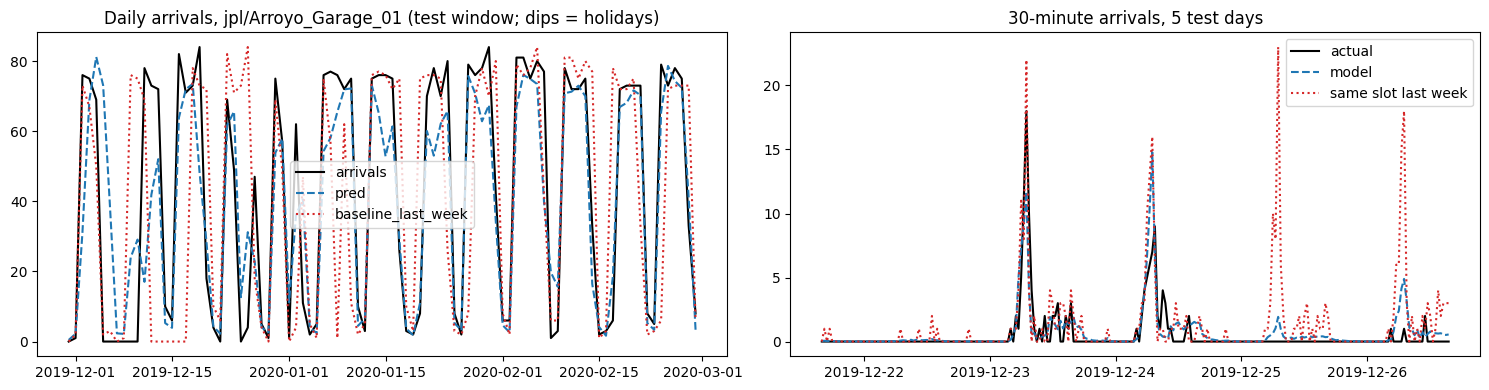

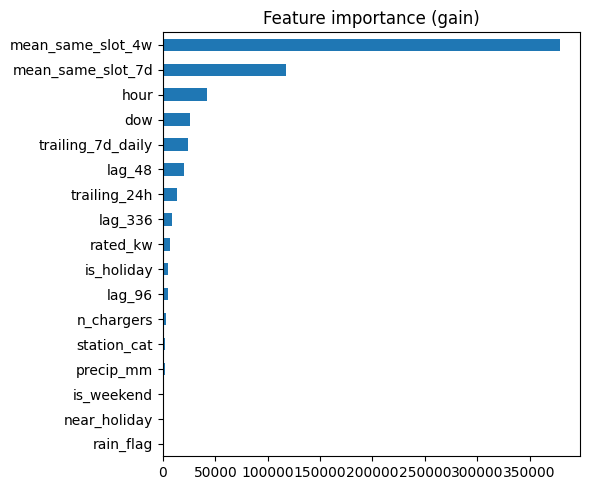

In [8]:
busiest = test.groupby("station")["arrivals"].sum().idxmax()
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
d = test[test["station"] == busiest]
daily = d.groupby(d["slot_local"].dt.date)[["arrivals","pred","baseline_last_week"]].sum()
daily.plot(ax=ax[0], style=["-","--",":"], color=["black","tab:blue","tab:red"])
ax[0].set_title(f"Daily arrivals, {busiest} (test window; dips = holidays)"); ax[0].set_xlabel("")
wk = d[(d["slot_local"] >= d["slot_local"].min() + pd.Timedelta(days=21)) & (d["slot_local"] < d["slot_local"].min() + pd.Timedelta(days=26))]
ax[1].plot(wk["slot_local"], wk["arrivals"], "k", label="actual"); ax[1].plot(wk["slot_local"], wk["pred"], "--", c="tab:blue", label="model")
ax[1].plot(wk["slot_local"], wk["baseline_last_week"], ":", c="tab:red", label="same slot last week"); ax[1].legend()
ax[1].set_title("30-minute arrivals, 5 test days"); plt.tight_layout(); plt.show()

imp = pd.Series(model.feature_importance("gain"), index=FEATURES).sort_values()
imp.plot.barh(figsize=(6, 5), title="Feature importance (gain)"); plt.tight_layout(); plt.show()

## 8. Arrivals → waiting time (M/M/c, Erlang C)
- λ = predicted arrivals per hour, µ = 1 / mean charging time, c = working chargers.
- ACN sites have dozens of chargers and long dwell, so queues are essentially zero as-is. To show the mechanism at R&R scale, the demo **keeps each charger's load and shrinks the station to `C_DEMO` chargers**, then applies the festive multiplier (an **assumption**).
- Faulty charger from Model 2 ⇒ call the same function with `c - 1`.

In [9]:
def erlang_c(c, a):
    """P(an arriving car has to wait) for M/M/c with offered load a = lambda/mu."""
    if a >= c: return 1.0
    term, s = 1.0, 0.0
    for k in range(c):
        s += term; term *= a / (k + 1)          # after loop: term = a^c / c!
    top = term * c / (c - a)
    return top / (s + top)

def wait_minutes(arrivals_per_slot, mean_service_min, c, cap=240.0):
    """Expected wait in queue (minutes) for a 30-min slot. cap keeps unstable queues plottable."""
    if c <= 0: return cap
    lam, mu = arrivals_per_slot * 2.0, 60.0 / mean_service_min          # per hour
    if lam <= 0: return 0.0
    if lam >= c * mu: return cap
    return min(cap, 60.0 * erlang_c(c, lam / mu) / (c * mu - lam))

# sanity checks against textbook values
assert abs(erlang_c(2, 1.0) - 1/3) < 1e-9               # Erlang C(c=2, a=1) = 1/3
assert abs(wait_minutes(0.25, 60, 1) - 60.0) < 1e-9     # M/M/1, lam=0.5/h, mu=1/h -> Wq = rho/(mu-lam) = 1 h
print("queue maths OK")

queue maths OK


Demo station: jpl/Arroyo_Garage_01  |  service time used 35 min (learned from ACN: 222) |  real chargers 52 -> demo 4
Peak slot 2020-01-08 07:00:00: predicted 0.90 arrivals / 30 min at demo scale


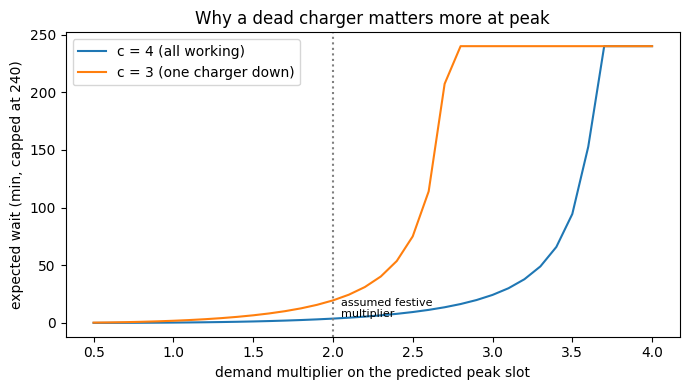

At the peak slot with the festive multiplier (2.0x): wait 4 min with 4 chargers vs 20 min with 3.


In [10]:
# ---- demo station: busiest station, shrunk to C_DEMO chargers at the same per-charger load ----
svc = (SERVICE_MIN_OVERRIDE or float(profile.loc[busiest, "mean_charge_min"]))
scale = C_DEMO / profile.loc[busiest, "n_chargers"]
d = test[test["station"] == busiest].copy()
d["demo_arrivals"] = d["pred"] * scale
peak_slot = d.loc[d["demo_arrivals"].nlargest(max(1, int(len(d) * 0.01))).index].iloc[-1]   # ~99th-percentile predicted slot
base_arr = float(peak_slot["demo_arrivals"])
print(f"Demo station: {busiest}  |  service time used {svc:.0f} min (learned from ACN: {profile.loc[busiest,'mean_charge_min']:.0f}) |  real chargers {int(profile.loc[busiest,'n_chargers'])} -> demo {C_DEMO}")
print(f"Peak slot {peak_slot['slot_local']}: predicted {base_arr:.2f} arrivals / 30 min at demo scale")

mults = np.linspace(0.5, 4.0, 36)
w_c   = [wait_minutes(base_arr * m, svc, C_DEMO)     for m in mults]
w_cm1 = [wait_minutes(base_arr * m, svc, C_DEMO - 1) for m in mults]
plt.figure(figsize=(7, 4)); plt.plot(mults, w_c, label=f"c = {C_DEMO} (all working)"); plt.plot(mults, w_cm1, label=f"c = {C_DEMO-1} (one charger down)")
plt.axvline(FESTIVE_MULT, ls=":", c="grey"); plt.text(FESTIVE_MULT + 0.05, 5, "assumed festive\nmultiplier", fontsize=8)
plt.xlabel("demand multiplier on the predicted peak slot"); plt.ylabel("expected wait (min, capped at 240)")
plt.title("Why a dead charger matters more at peak"); plt.legend(); plt.tight_layout(); plt.show()

ok  = wait_minutes(base_arr * FESTIVE_MULT, svc, C_DEMO)
bad = wait_minutes(base_arr * FESTIVE_MULT, svc, C_DEMO - 1)
print(f"At the peak slot with the festive multiplier ({FESTIVE_MULT}x): wait {ok:.0f} min with {C_DEMO} chargers vs {bad:.0f} min with {C_DEMO-1}.")

## 9. Export for Model 2 and the priority engine
`recompute_wait()` is the hook: Model 2 passes the number of *working* chargers and gets the new wait for each slot. Wait columns here are at **demo scale** and use the festive multiplier assumption, so label them as simulated.

In [11]:
def recompute_wait(pred_df, station, working_chargers, demand_mult=1.0, service_min=None):
    """Wait time (min) per slot for `station` if only `working_chargers` are up. Demo-scale demand."""
    sv = service_min or SERVICE_MIN_OVERRIDE or float(profile.loc[station, "mean_charge_min"])
    sc = C_DEMO / profile.loc[station, "n_chargers"]
    return pred_df["pred"].apply(lambda a: wait_minutes(a * sc * demand_mult, sv, working_chargers))

export = test[["station","slot_utc","slot_local","arrivals","pred","baseline_last_week","is_holiday","near_holiday"]].copy()
export["wait_min_all_up"]  = np.nan
export["wait_min_one_down"] = np.nan
for st in STATIONS:
    m = export["station"] == st
    export.loc[m, "wait_min_all_up"]   = recompute_wait(export[m], st, C_DEMO,     FESTIVE_MULT).values
    export.loc[m, "wait_min_one_down"] = recompute_wait(export[m], st, C_DEMO - 1, FESTIVE_MULT).values

export.to_csv(OUT / "model1_test_predictions.csv", index=False)
profile.to_csv(OUT / "station_profile.csv")
model.save_model(str(OUT / "model1_lgbm.txt"), num_iteration=model.best_iteration)
summary = dict(horizon_hours=HORIZON_HOURS, stations=STATIONS, features=FEATURES, rain_features_used=RAIN_OK,
               best_iteration=int(model.best_iteration), festive_multiplier_assumed=FESTIVE_MULT, demo_chargers=C_DEMO,
               test_metrics=metrics.round(4).reset_index().to_dict(orient="records"))
(OUT / "model1_metrics.json").write_text(json.dumps(summary, indent=2, default=str))
print("Saved:", *sorted(p.name for p in OUT.iterdir()), sep="\n  ")

Saved:
  model1_lgbm.txt
  model1_metrics.json
  model1_test_predictions.csv
  station_profile.csv


## Notes and next steps
- **Backtest (workstream E):** use `outputs/model1_test_predictions.csv`. Baseline = same slot last week; ours = model forecast; waits come from `recompute_wait`.
- **Malaysian corridor (workstream A):** swap `LOCAL_TZ`, `HOLIDAYS`, `LAT/LON`, replace the ACN station table with the MEVnet / Open Charge Map stations, and scale arrivals by the festive and rain multipliers. All multipliers are assumptions, so state them in the pitch.
- **Model 2 hook:** when a charger is flagged, call `recompute_wait(..., working_chargers=c-1)` and multiply extra waiting / lost sessions by RM per session for the priority score.
- **Rain features:** archived actuals stand in for forecasts. In production use the Open-Meteo forecast endpoint.
- **Robustness:** rerun with a different `SITES` list, `N_SAMPLE`, `HORIZON_HOURS` (24 / 48 / 72) or seed to show results hold.